# JOBSHEET 06 DL: Teknik Segmentasi Gambar 2 (Segmentasi Instans dan Segmentasi Promptable)
Mata kuliah Visi Komputer, Politeknik Negeri Semarang. Dosen: Ir. Prayitno, S.ST., M.T., Ph.D.

Isi: D1 data instans Penn-Fudan, D2 Mask R-CNN pra-latih COCO, D3 fine-tuning ringan Mask R-CNN,
D4 evaluasi mask (IoU dan AP), D5 Segment Anything (SAM) dengan prompt titik dan kotak,
D6 mini-proyek penghapus latar otomatis (deteksi lalu SAM) pada foto hewan peliharaan.

**Cara pakai di Google Colab:** Runtime > Change runtime type > T4 GPU, lalu Runtime > Run all.

| Bagian | Perkiraan waktu Colab T4 (mode PENUH) | Waktu nyata di CPU box (mode CEPAT) |
|---|---|---|
| Instalasi + unduh Penn-Fudan (51 MB) + bobot | 2 sampai 4 menit | lihat output sel |
| D2 inferensi Mask R-CNN pra-latih | kurang dari 1 menit | lihat output sel |
| D3 fine-tuning Mask R-CNN | sekitar 6 sampai 10 menit | lihat output sel |
| D4 evaluasi | kurang dari 1 menit | lihat output sel |
| D5 SAM ViT-B (unduh 375 MB + inferensi) | 2 sampai 3 menit | lihat output sel |
| D6 mini-proyek | 1 sampai 3 menit | lihat output sel |

Perkiraan waktu Colab adalah estimasi, bukan hasil pengukuran. Tanpa GPU, notebook otomatis memakai mode CEPAT.

In [2]:
# === Persiapan 1: instalasi pustaka ===
%pip install -q transformers

In [3]:
# === Persiapan 2: impor, cek GPU, seed, konfigurasi ===
import os, time, random, json, zipfile, urllib.request, gc
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torchvision
import torchvision.transforms.functional as TF

def set_seed(seed=42):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CEPAT = DEVICE == "cpu"
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("Perangkat:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU saja")
CFG = dict(
    N_TEST    = 20 if CEPAT else 50,    # citra uji Penn-Fudan
    N_TRAIN   = 60 if CEPAT else 120,   # citra latih untuk fine-tuning
    EPOCHS    = 1 if CEPAT else 6,
    MIN_SIZE  = 320 if CEPAT else 512,  # sisi terpendek citra di dalam Mask R-CNN
    MAX_SIZE  = 544 if CEPAT else 853,
    N_SAM     = 6 if CEPAT else 20,     # citra uji untuk eksperimen SAM
    N_PROYEK  = 8 if CEPAT else 30,     # foto hewan untuk mini-proyek
)
print("Mode:", "CEPAT (CPU)" if CEPAT else "PENUH (GPU)", CFG)
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
WAKTU = {}

PyTorch 2.14.1+cu130 | torchvision 0.29.1+cu130
Perangkat: cuda | Tesla T4
Mode: PENUH (GPU) {'N_TEST': 50, 'N_TRAIN': 120, 'EPOCHS': 6, 'MIN_SIZE': 512, 'MAX_SIZE': 853, 'N_SAM': 20, 'N_PROYEK': 30}


## Praktikum D1: Mengenal Data Segmentasi Instans (Penn-Fudan Pedestrian)
Penn-Fudan Pedestrian Database (Wang dkk., 2007): 170 citra, 345 pejalan kaki berlabel, setiap orang memiliki masker sendiri
(nilai piksel 0 = latar, 1, 2, 3, ... = ID orang). Sumber resmi: https://www.cis.upenn.edu/~jshi/ped_html/

**Catatan lisensi:** halaman resmi dan `readme.txt` tidak mencantumkan lisensi terbuka; hak cipta tetap pada penulis.
Gunakan hanya untuk belajar, unduh langsung dari sumber resmi, jangan unggah ulang datanya, dan sitasi makalah aslinya.

In [4]:
# === D1.1 Unduh dan ekstrak Penn-Fudan ===
t0 = time.time()
os.makedirs("data", exist_ok=True)
if not os.path.isdir("data/PennFudanPed"):
    urllib.request.urlretrieve("https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip", "data/PennFudanPed.zip")
    with zipfile.ZipFile("data/PennFudanPed.zip") as z:
        z.extractall("data")
PF = "data/PennFudanPed"
NAMA = sorted(os.listdir(f"{PF}/PNGImages"))
print("Jumlah citra:", len(NAMA), "| waktu %.1f s" % (time.time() - t0))

Jumlah citra: 170 | waktu 2.8 s


In [5]:
# === D1.2 Dataset instans: boxes, labels, masks per orang ===
class PennFudan(torch.utils.data.Dataset):
    def __init__(self, nama, augment=False):
        self.nama, self.augment = nama, augment
    def __len__(self):
        return len(self.nama)
    def muat(self, i):
        n = self.nama[i]
        img = Image.open(f"{PF}/PNGImages/{n}").convert("RGB")
        m = np.array(Image.open(f"{PF}/PedMasks/{n[:-4]}_mask.png"))
        ids = np.unique(m); ids = ids[ids != 0]                 # buang latar (0)
        masks = (m[None] == ids[:, None, None])                  # (N,H,W) bool, satu per orang
        return img, masks
    def __getitem__(self, i):
        img, masks = self.muat(i)
        x = TF.to_tensor(img)
        masks = torch.from_numpy(masks).to(torch.uint8)
        if self.augment and random.random() < 0.5:
            x, masks = x.flip(-1), masks.flip(-1)
        boxes = []
        for mk in masks:
            ys, xs = torch.where(mk > 0)
            boxes.append([xs.min(), ys.min(), xs.max() + 1, ys.max() + 1])
        target = {"boxes": torch.tensor(boxes, dtype=torch.float32),
                  "labels": torch.ones(len(masks), dtype=torch.int64),   # 1 = pejalan kaki
                  "masks": masks}
        return x, target

rng = random.Random(0); acak = NAMA[:]; rng.shuffle(acak)
NAMA_TEST, NAMA_TRAIN = acak[:CFG["N_TEST"]], acak[50:50 + CFG["N_TRAIN"]]   # 50 citra pertama dicadangkan untuk uji
ds_all = PennFudan(NAMA)
jml = [len(ds_all.muat(i)[1]) for i in range(len(NAMA))]
print("Total pejalan kaki berlabel:", sum(jml), "| rata-rata per citra: %.2f | maks: %d" % (np.mean(jml), max(jml)))
ds_train = PennFudan(NAMA_TRAIN, augment=True); ds_test = PennFudan(NAMA_TEST)
x, t = ds_test[0]
print("x:", tuple(x.shape), "| boxes:", tuple(t["boxes"].shape), "| masks:", tuple(t["masks"].shape))

Total pejalan kaki berlabel: 423 | rata-rata per citra: 2.49 | maks: 8
x: (3, 344, 374) | boxes: (1, 4) | masks: (1, 344, 374)


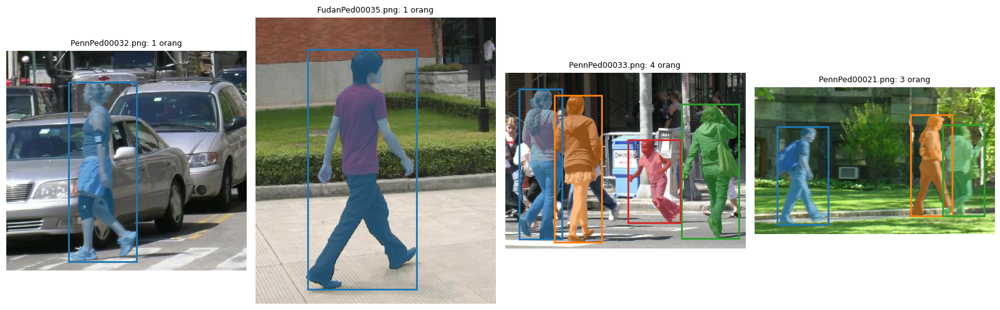

In [6]:
# === D1.3 Visualisasi masker instans: setiap orang diberi warna berbeda ===
WARNA = plt.cm.tab10(np.arange(10))[:, :3]
def overlay(img, masks, boxes=None, alpha=0.5, judul=None, ax=None):
    arr = np.array(img).astype(float) / 255
    for k, mk in enumerate(masks):
        mk = np.asarray(mk).astype(bool)
        arr[mk] = (1 - alpha) * arr[mk] + alpha * WARNA[k % 10]
    ax.imshow(arr)
    if boxes is not None:
        for k, b in enumerate(boxes):
            b = [float(v) for v in b]
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=WARNA[k % 10], lw=2))
    if judul: ax.set_title(judul, fontsize=9)
    ax.axis("off")

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    img, masks = ds_test.muat(j); _, t = ds_test[j]
    overlay(img, masks, t["boxes"], judul=f"{NAMA_TEST[j]}: {len(masks)} orang", ax=ax[j])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d1_contoh_instans.png", dpi=110); plt.show()

**Tugas kecil D1:** Jelaskan perbedaan keluaran segmentasi semantik (JS05) dan segmentasi instans pada citra yang berisi tiga orang.

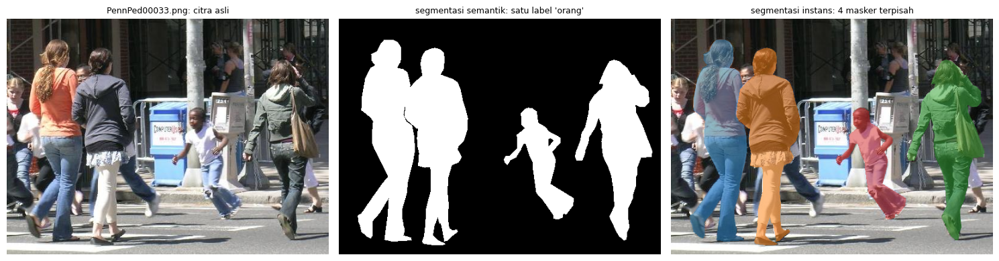

Label unik peta semantik: [0, 1] (0 = latar, 1 = orang)
Jumlah orang menurut GT instans: 4 | luas tiap orang (piksel): [18733, 18096, 17055, 7496]
Komponen terhubung pada peta semantik: 3 (lebih sedikit dari 4 bila ada orang yang saling menempel)


In [7]:
from scipy import ndimage

j1 = next((i for i in range(len(ds_test)) if len(ds_test.muat(i)[1]) >= 3), 0)
img1, m1 = ds_test.muat(j1)
semantik = m1.any(0)
n_komp = ndimage.label(semantik)[1]

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img1); ax[0].set_title(f"{NAMA_TEST[j1]}: citra asli", fontsize=9); ax[0].axis("off")
ax[1].imshow(semantik, cmap="gray"); ax[1].set_title("segmentasi semantik: satu label 'orang'", fontsize=9); ax[1].axis("off")
overlay(img1, m1, judul=f"segmentasi instans: {len(m1)} masker terpisah", ax=ax[2])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d1_semantik_vs_instans.png", dpi=110); plt.show()

print(f"Label unik peta semantik: {np.unique(semantik.astype(int)).tolist()} (0 = latar, 1 = orang)")
print(f"Jumlah orang menurut GT instans: {len(m1)} | luas tiap orang (piksel): {[int(mk.sum()) for mk in m1]}")
print(f"Komponen terhubung pada peta semantik: {n_komp} (lebih sedikit dari {len(m1)} bila ada orang yang saling menempel)")

**Jawaban D1.** Pada citra yang berisi tiga orang:

| | Segmentasi semantik (JS05) | Segmentasi instans (JS06) |
|---|---|---|
| Keluaran | satu peta label per piksel (0 = latar, 1 = orang) | satu masker biner per orang, ditambah kotak, kelas, dan skor |
| Tiga orang | menjadi satu wilayah berlabel "orang" yang sama | menjadi tiga masker dengan identitas terpisah |
| Menghitung orang | tidak bisa langsung; orang yang berdekatan atau saling menutupi menyatu menjadi satu gumpalan | jumlah masker sama dengan jumlah orang |
| Orang yang bertumpuk | batas antar orang hilang karena labelnya sama | tiap orang tetap punya masker sendiri |
| Cocok untuk | luas wilayah suatu kelas (jalan, langit, rumput) | memisahkan, menghitung, mengukur, atau memotong tiap objek |

Sel di atas memperlihatkannya: peta semantik hanya berisi label 0 dan 1, sedangkan GT instans berisi satu masker untuk setiap orang. Jumlah komponen terhubung pada peta semantik tidak lebih dari jumlah orang sebenarnya, dan lebih sedikit bila ada orang yang saling menempel.

## Praktikum D2: Mask R-CNN Pra-Latih COCO (tanpa pelatihan)
Mask R-CNN (He dkk., 2017) menambahkan cabang prediksi masker pada detektor Faster R-CNN. Bobot torchvision dilatih pada COCO
(80 kelas, kelas 1 = *person*), sehingga dapat langsung mendeteksi pejalan kaki.

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth


100%|██████████| 170M/170M [00:01<00:00, 155MB/s]


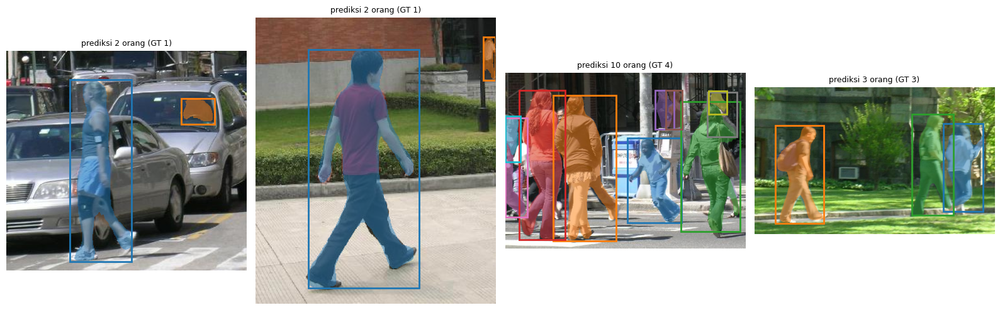

Waktu inferensi 4 citra: 4.6 s


In [8]:
# === D2.1 Muat Mask R-CNN pra-latih dan lakukan inferensi ===
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
W = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
mrcnn_coco = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"]).to(DEVICE).eval()
KATEGORI = W.meta["categories"]

@torch.no_grad()
def deteksi(model, x, label_orang=1, skor_min=0.5):
    out = model([x.to(DEVICE)])[0]
    keep = (out["labels"] == label_orang) & (out["scores"] >= skor_min)
    return {k: v[keep].cpu() for k, v in out.items()}

t0 = time.time()
fig, ax = plt.subplots(1, 4, figsize=(16, 5))
for j in range(4):
    x, t = ds_test[j]; img, _ = ds_test.muat(j)
    o = deteksi(mrcnn_coco, x)
    overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul=f"prediksi {len(o['scores'])} orang (GT {len(t['labels'])})", ax=ax[j])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d2_maskrcnn_coco.png", dpi=110); plt.show()
print("Waktu inferensi 4 citra: %.1f s" % (time.time() - t0))

**Tugas kecil D2:** Ubah `skor_min` menjadi 0,3 dan 0,8. Berapa jumlah deteksi yang berubah? Apa risikonya bila ambang terlalu rendah?

Jumlah orang pada GT: 126 dari 50 citra uji
skor_min  deteksi  beda vs 0,5  tanpa pasangan GT  GT terlewat
     0.3      308          +57                181            0
     0.5      251           +0                125            0
     0.8      200          -51                 74            0


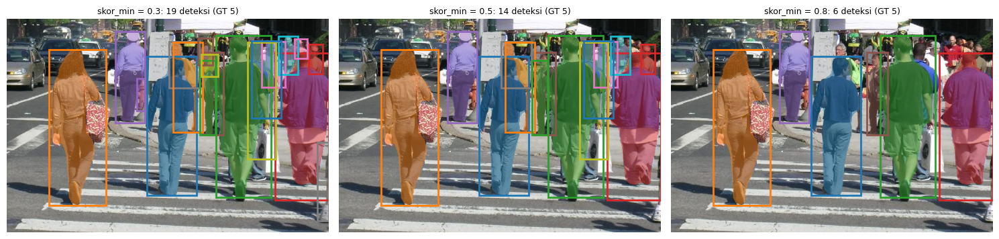

Waktu: 7.1 s


In [9]:
t0 = time.time()
KELUARAN = []
for i in range(len(ds_test)):
    x, t = ds_test[i]
    o = deteksi(mrcnn_coco, x, skor_min=0.05)
    KELUARAN.append(dict(skor=o["scores"], boxes=o["boxes"], masks=o["masks"][:, 0] > 0.5, gt=t["masks"].bool()))

def iou_kecil(a, b):
    a = a.reshape(len(a), -1).float(); b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

TABEL_D2 = []
for thr in (0.3, 0.5, 0.8):
    n_det = n_fp = n_fn = 0
    for k in KELUARAN:
        P = k["masks"][k["skor"] >= thr]; G = k["gt"]
        n_det += len(P)
        if len(P) == 0:
            n_fn += len(G); continue
        M = iou_kecil(P, G)
        n_fp += int((M.max(1).values < 0.5).sum())
        n_fn += int((M.max(0).values < 0.5).sum())
    TABEL_D2.append(dict(skor_min=thr, deteksi=n_det, tanpa_pasangan_gt=n_fp, gt_terlewat=n_fn))

n_gt = sum(len(k["gt"]) for k in KELUARAN)
dasar_det = TABEL_D2[1]["deteksi"]
print(f"Jumlah orang pada GT: {n_gt} dari {len(KELUARAN)} citra uji")
print(f"{'skor_min':>8s} {'deteksi':>8s} {'beda vs 0,5':>12s} {'tanpa pasangan GT':>18s} {'GT terlewat':>12s}")
for r in TABEL_D2:
    print(f"{r['skor_min']:8.1f} {r['deteksi']:8d} {r['deteksi'] - dasar_det:+12d} {r['tanpa_pasangan_gt']:18d} {r['gt_terlewat']:12d}")

i_vis = max(range(len(KELUARAN)), key=lambda i: int((KELUARAN[i]["skor"] >= 0.3).sum() - (KELUARAN[i]["skor"] >= 0.8).sum()))
img_v = ds_test.muat(i_vis)[0]; kv = KELUARAN[i_vis]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a_, thr in zip(ax, (0.3, 0.5, 0.8)):
    s = kv["skor"] >= thr
    overlay(img_v, kv["masks"][s].numpy(), kv["boxes"][s], judul=f"skor_min = {thr}: {int(s.sum())} deteksi (GT {len(kv['gt'])})", ax=a_)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d2_ambang_skor.png", dpi=110); plt.show()
print("Waktu: %.1f s" % (time.time() - t0))

**Jawaban D2.** Tabel pada sel di atas membandingkan `skor_min` 0,3, 0,5, dan 0,8. Jumlah deteksi selalu bertambah saat ambang diturunkan dan berkurang saat ambang dinaikkan, karena himpunan deteksi pada ambang tinggi adalah bagian dari himpunan pada ambang rendah. Kolom "beda vs 0,5" memberi jumlah deteksi yang berubah, dan gambar memperlihatkan citra dengan perubahan terbesar.

Risiko ambang terlalu rendah (misalnya 0,3):
- muncul deteksi palsu: objek yang bukan orang, bagian tubuh, atau kotak ganda pada orang yang sama (kolom "tanpa pasangan GT" naik)
- presisi turun, dan masker yang salah ikut terbawa ke tahap berikutnya (penghitungan orang, atau kotak yang dijadikan prompt SAM)

Risiko ambang terlalu tinggi (misalnya 0,8):
- orang yang kecil, terhalang, atau gelap terlewat (kolom "GT terlewat" naik), sehingga recall turun

Karena itu `evaluasi_instans` memakai ambang sangat rendah (0,05) agar kurva presisi-recall lengkap, sedangkan ambang kerja dipilih menurut biaya kesalahan: ambang tinggi bila deteksi palsu lebih merugikan, ambang rendah bila kehilangan objek lebih merugikan.

## Praktikum D4 (dikerjakan sebelum D3): Fungsi Evaluasi Mask (IoU dan AP)
Kita membuat evaluator ringan: setiap prediksi dicocokkan dengan masker GT yang belum terpakai (urut skor tertinggi).
Prediksi dianggap benar (TP) bila IoU masker ≥ ambang. Dari kurva presisi-recall dihitung **AP** (Average Precision).
AP50 memakai ambang 0,5; AP[.50:.95] adalah rata-rata AP pada ambang 0,50 sampai 0,95 (gaya COCO).

In [10]:
# === D4.1 Evaluator mask: IoU, AP50, AP[.50:.95] ===
def iou_mask(a, b):
    # a: (P,H,W) bool, b: (G,H,W) bool  ->  (P,G)
    a = a.reshape(len(a), -1).float(); b = b.reshape(len(b), -1).float()
    inter = a @ b.T
    return inter / (a.sum(1, keepdim=True) + b.sum(1)[None] - inter).clamp_min(1)

def average_precision(skor, tp, npos):
    if len(skor) == 0: return 0.0, np.array([0.]), np.array([0.])
    o = np.argsort(-np.array(skor)); tp = np.array(tp)[o]
    ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
    rec = ctp / max(npos, 1); prec = ctp / np.maximum(ctp + cfp, 1e-9)
    mrec = np.r_[0, rec, 1]; mpre = np.r_[0, prec, 0]
    for i in range(len(mpre) - 2, -1, -1): mpre[i] = max(mpre[i], mpre[i + 1])
    i = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[i + 1] - mrec[i]) * mpre[i + 1])), rec, prec

@torch.no_grad()
def evaluasi_instans(model, ds, label_orang=1, skor_min=0.05):
    model.eval(); semua = []
    for i in range(len(ds)):
        x, t = ds[i]
        o = deteksi(model, x, label_orang, skor_min)
        P = o["masks"][:, 0] > 0.5; G = t["masks"].bool()
        semua.append((o["scores"].numpy(), iou_mask(P, G) if len(P) else torch.zeros(0, len(G)), len(G)))
    npos = sum(s[2] for s in semua); hasil = {}
    for thr in np.arange(0.5, 0.96, 0.05):
        skor, tp, iou_cocok = [], [], []
        for sc, M, g in semua:
            pakai = set()
            for p in np.argsort(-sc):
                skor.append(sc[p]); best, bj = 0, -1
                for j in range(g):
                    if j not in pakai and M[p, j] > best: best, bj = M[p, j].item(), j
                if best >= thr: pakai.add(bj); tp.append(1); iou_cocok.append(best)
                else: tp.append(0)
        ap, rec, prec = average_precision(skor, tp, npos)
        hasil[round(float(thr), 2)] = (ap, rec, prec, iou_cocok)
    return {"AP50": hasil[0.5][0], "AP75": hasil[0.75][0],
            "AP[.50:.95]": float(np.mean([v[0] for v in hasil.values()])),
            "mIoU_cocok@0.5": float(np.mean(hasil[0.5][3])) if hasil[0.5][3] else 0.0,
            "Recall@0.5": float(hasil[0.5][1][-1]), "jumlah_GT": npos, "_pr": hasil[0.5][1:3]}

t0 = time.time()
HASIL = {"Mask R-CNN COCO (tanpa latih)": evaluasi_instans(mrcnn_coco, ds_test)}
WAKTU["Evaluasi COCO zero-shot"] = time.time() - t0
ringkas = lambda m: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in m.items() if not k.startswith("_")}
print(ringkas(HASIL["Mask R-CNN COCO (tanpa latih)"]), "| %.1f s" % WAKTU["Evaluasi COCO zero-shot"])

{'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126} | 12.7 s


## Praktikum D3: Fine-Tuning Ringan Mask R-CNN untuk Kelas Pejalan Kaki
Kepala klasifikasi kotak dan kepala masker diganti menjadi 2 kelas (latar + pejalan kaki). Backbone ResNet-50 dibekukan
agar pelatihan ringan; hanya RPN, kepala kotak, dan kepala masker yang dilatih.

In [11]:
# === D3.1 Siapkan model 2 kelas ===
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor
set_seed(42)
mrcnn_ft = maskrcnn_resnet50_fpn(weights=W, min_size=CFG["MIN_SIZE"], max_size=CFG["MAX_SIZE"])
in_feat = mrcnn_ft.roi_heads.box_predictor.cls_score.in_features
mrcnn_ft.roi_heads.box_predictor = FastRCNNPredictor(in_feat, 2)
mrcnn_ft.roi_heads.mask_predictor = MaskRCNNPredictor(256, 256, 2)
for p in mrcnn_ft.backbone.body.parameters():
    p.requires_grad = False           # bekukan ResNet-50
mrcnn_ft = mrcnn_ft.to(DEVICE)
dilatih = [p for p in mrcnn_ft.parameters() if p.requires_grad]
print("Parameter dilatih: %.2f juta dari %.2f juta" % (sum(p.numel() for p in dilatih) / 1e6, sum(p.numel() for p in mrcnn_ft.parameters()) / 1e6))

Parameter dilatih: 20.47 juta dari 43.92 juta


In [12]:
# === D3.2 Loop pelatihan ===
collate = lambda b: tuple(zip(*b))
dl_train = torch.utils.data.DataLoader(ds_train, batch_size=2, shuffle=True, collate_fn=collate)
opt = torch.optim.SGD(dilatih, lr=0.005, momentum=0.9, weight_decay=5e-4)
riwayat = []; t0 = time.time()
for ep in range(CFG["EPOCHS"]):
    mrcnn_ft.train()
    for it, (xs, ts) in enumerate(dl_train):
        xs = [x.to(DEVICE) for x in xs]; ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
        losses = mrcnn_ft(xs, ts)                 # mode latih: keluaran berupa dict loss
        loss = sum(losses.values())
        opt.zero_grad(); loss.backward(); opt.step()
        riwayat.append({k: v.item() for k, v in losses.items()} | {"total": loss.item()})
        if it % 10 == 0:
            print(f"epoch {ep+1} iterasi {it:3d}  loss total {loss.item():.3f}  mask {losses['loss_mask'].item():.3f}  ({time.time()-t0:.0f} s)")
WAKTU["Fine-tuning Mask R-CNN"] = time.time() - t0
print("Waktu fine-tuning: %.1f s untuk %d iterasi" % (WAKTU["Fine-tuning Mask R-CNN"], len(riwayat)))

epoch 1 iterasi   0  loss total 2.387  mask 1.320  (1 s)
epoch 1 iterasi  10  loss total 0.306  mask 0.157  (3 s)
epoch 1 iterasi  20  loss total 0.467  mask 0.190  (6 s)
epoch 1 iterasi  30  loss total 0.357  mask 0.172  (8 s)
epoch 1 iterasi  40  loss total 0.288  mask 0.170  (11 s)
epoch 1 iterasi  50  loss total 0.320  mask 0.163  (13 s)
epoch 2 iterasi   0  loss total 0.168  mask 0.112  (16 s)
epoch 2 iterasi  10  loss total 0.400  mask 0.187  (18 s)
epoch 2 iterasi  20  loss total 0.238  mask 0.133  (21 s)
epoch 2 iterasi  30  loss total 0.287  mask 0.142  (23 s)
epoch 2 iterasi  40  loss total 0.169  mask 0.129  (26 s)
epoch 2 iterasi  50  loss total 0.267  mask 0.142  (28 s)
epoch 3 iterasi   0  loss total 0.197  mask 0.140  (31 s)
epoch 3 iterasi  10  loss total 0.188  mask 0.116  (34 s)
epoch 3 iterasi  20  loss total 0.151  mask 0.105  (36 s)
epoch 3 iterasi  30  loss total 0.293  mask 0.135  (39 s)
epoch 3 iterasi  40  loss total 0.241  mask 0.136  (41 s)
epoch 3 iterasi  5

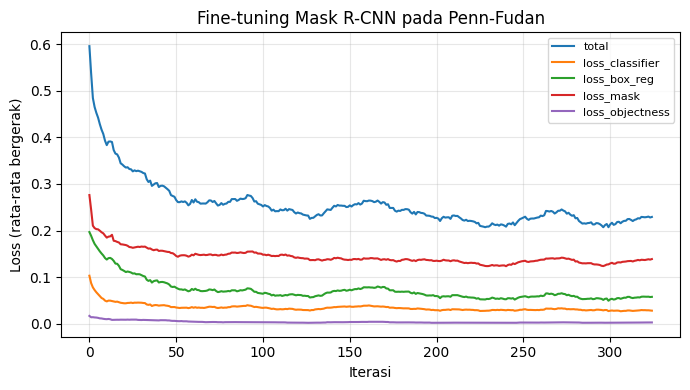

In [13]:
# === D3.3 Kurva loss fine-tuning ===
plt.figure(figsize=(7, 4))
for k in ["total", "loss_classifier", "loss_box_reg", "loss_mask", "loss_objectness"]:
    v = np.array([r[k] for r in riwayat]); w = max(1, len(v) // 10)
    plt.plot(np.convolve(v, np.ones(w) / w, mode="valid"), label=k)
plt.xlabel("Iterasi"); plt.ylabel("Loss (rata-rata bergerak)"); plt.title("Fine-tuning Mask R-CNN pada Penn-Fudan")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d3_kurva_finetune.png", dpi=120); plt.show()

Mask R-CNN COCO (tanpa latih)       {'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Mask R-CNN fine-tuned Penn-Fudan    {'AP50': 0.9901, 'AP75': 0.9574, 'AP[.50:.95]': 0.7722, 'mIoU_cocok@0.5': 0.8724, 'Recall@0.5': 1.0, 'jumlah_GT': 126}


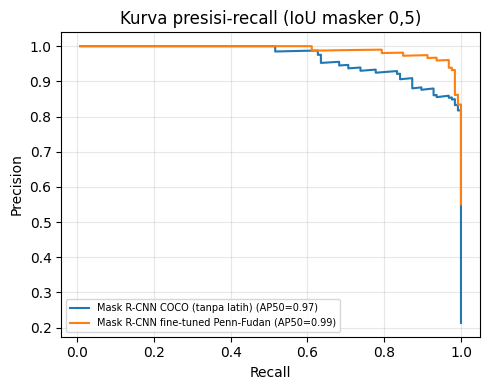

In [14]:
# === D4.2 Evaluasi model hasil fine-tuning dan bandingkan ===
t0 = time.time()
HASIL["Mask R-CNN fine-tuned Penn-Fudan"] = evaluasi_instans(mrcnn_ft, ds_test)
WAKTU["Evaluasi fine-tuned"] = time.time() - t0
for k, v in HASIL.items():
    print(f"{k:35s}", ringkas(v))
plt.figure(figsize=(5, 4))
for k, v in HASIL.items():
    rec, prec = v["_pr"]; plt.plot(rec, prec, label=f"{k} (AP50={v['AP50']:.2f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Kurva presisi-recall (IoU masker 0,5)")
plt.legend(fontsize=7); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(f"{FIG_DIR}/js06_d4_kurva_pr.png", dpi=120); plt.show()

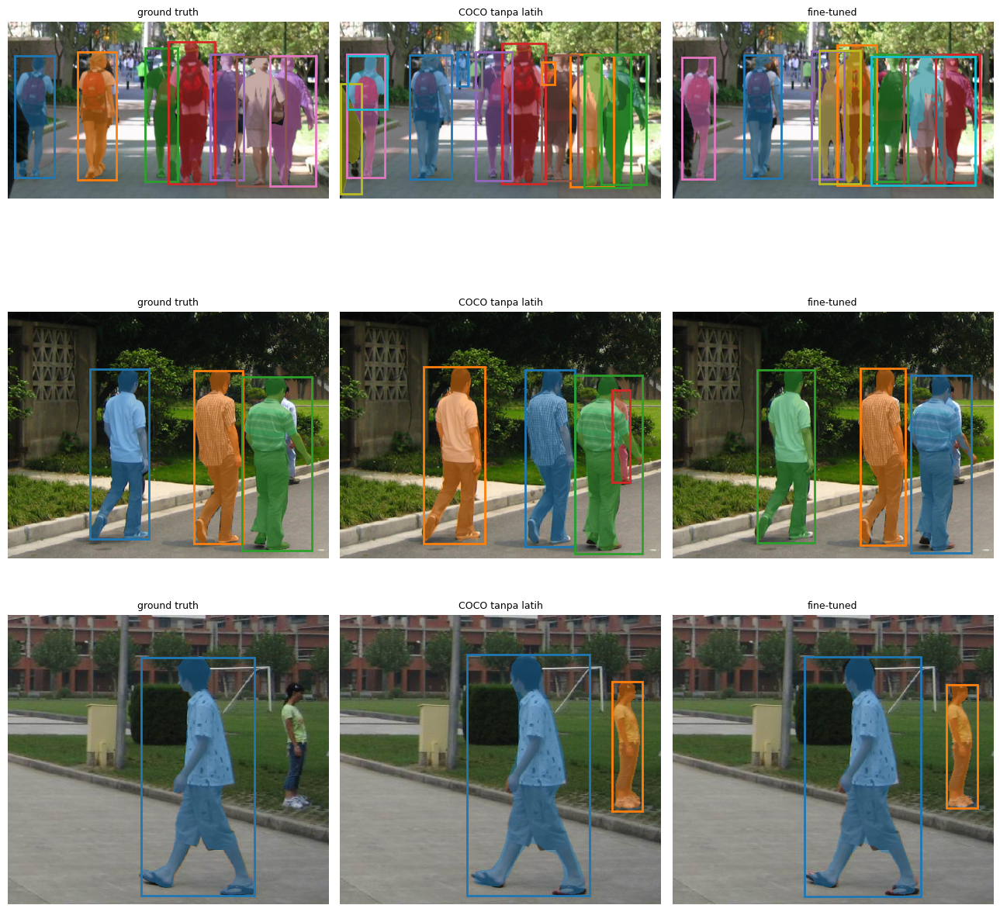

In [15]:
# === D4.3 Visual: GT vs COCO vs fine-tuned ===
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for r, j in enumerate([4, 5, 6]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j)
    overlay(img, gm, t["boxes"], judul="ground truth", ax=ax[r, 0])
    o = deteksi(mrcnn_coco, x); overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="COCO tanpa latih", ax=ax[r, 1])
    o = deteksi(mrcnn_ft, x);   overlay(img, (o["masks"][:, 0] > 0.5).numpy(), o["boxes"], judul="fine-tuned", ax=ax[r, 2])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d4_perbandingan.png", dpi=100); plt.show()

**Tugas kecil D3/D4:** Latih 2 sampai 3 epoch lagi (atau buka pembekuan `layer4` backbone). Apakah AP50 dan AP[.50:.95] naik?
Mengapa model COCO tanpa pelatihan sudah cukup baik untuk kelas orang?

In [16]:
import copy
LANJUT = 1 if CEPAT else 3

def latih_lanjut(model, epoch, lr=0.005, buka_layer4=False, seed=7):
    set_seed(seed)
    if buka_layer4:
        for p in model.backbone.body.layer4.parameters():
            p.requires_grad = True
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=5e-4)
    dl = torch.utils.data.DataLoader(ds_train, batch_size=2, shuffle=True, collate_fn=collate)
    log = []; t0 = time.time()
    for ep in range(epoch):
        model.train(); total = []
        for xs, ts in dl:
            xs = [x.to(DEVICE) for x in xs]
            ts = [{k: v.to(DEVICE) for k, v in t.items()} for t in ts]
            losses = model(xs, ts); loss = sum(losses.values())
            opt.zero_grad(); loss.backward(); opt.step()
            total.append(loss.item())
        log.append(float(np.mean(total)))
        print(f"  epoch lanjutan {ep + 1}/{epoch}  loss rata-rata {log[-1]:.3f}  ({time.time() - t0:.0f} s)")
    return log, sum(p.numel() for p in params)

t0 = time.time()
print(f"[A] lanjut {LANJUT} epoch, backbone tetap beku")
model_a = copy.deepcopy(mrcnn_ft)
loss_a, par_a = latih_lanjut(model_a, LANJUT)
print(f"[B] lanjut {LANJUT} epoch, layer4 backbone dibuka")
model_b = copy.deepcopy(mrcnn_ft)
loss_b, par_b = latih_lanjut(model_b, LANJUT, buka_layer4=True)
print("Parameter dilatih A: %.2f juta | B: %.2f juta" % (par_a / 1e6, par_b / 1e6))
WAKTU["Fine-tuning lanjutan (A dan B)"] = time.time() - t0
print("Waktu: %.1f s" % WAKTU["Fine-tuning lanjutan (A dan B)"])

[A] lanjut 3 epoch, backbone tetap beku
  epoch lanjutan 1/3  loss rata-rata 0.213  (16 s)
  epoch lanjutan 2/3  loss rata-rata 0.204  (32 s)
  epoch lanjutan 3/3  loss rata-rata 0.204  (49 s)
[B] lanjut 3 epoch, layer4 backbone dibuka
  epoch lanjutan 1/3  loss rata-rata 0.220  (17 s)
  epoch lanjutan 2/3  loss rata-rata 0.203  (34 s)
  epoch lanjutan 3/3  loss rata-rata 0.199  (51 s)
Parameter dilatih A: 20.47 juta | B: 35.41 juta
Waktu: 100.2 s


Mask R-CNN COCO (tanpa latih)                 {'AP50': 0.9657, 'AP75': 0.898, 'AP[.50:.95]': 0.7162, 'mIoU_cocok@0.5': 0.8583, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Mask R-CNN fine-tuned Penn-Fudan              {'AP50': 0.9901, 'AP75': 0.9574, 'AP[.50:.95]': 0.7722, 'mIoU_cocok@0.5': 0.8724, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Fine-tuned + 3 epoch (backbone beku)          {'AP50': 0.992, 'AP75': 0.9504, 'AP[.50:.95]': 0.7778, 'mIoU_cocok@0.5': 0.8749, 'Recall@0.5': 1.0, 'jumlah_GT': 126}
Fine-tuned + 3 epoch (layer4 dibuka)          {'AP50': 0.9909, 'AP75': 0.9597, 'AP[.50:.95]': 0.7634, 'mIoU_cocok@0.5': 0.8718, 'Recall@0.5': 1.0, 'jumlah_GT': 126}


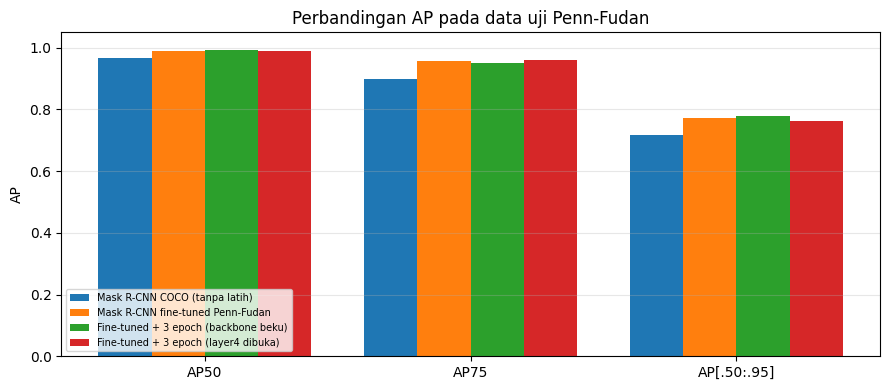


Fine-tuned + 3 epoch (backbone beku)          AP50         0.9901 -> 0.9920  (naik 0.0019)
Fine-tuned + 3 epoch (backbone beku)          AP[.50:.95]  0.7722 -> 0.7778  (naik 0.0056)
Fine-tuned + 3 epoch (layer4 dibuka)          AP50         0.9901 -> 0.9909  (naik 0.0008)
Fine-tuned + 3 epoch (layer4 dibuka)          AP[.50:.95]  0.7722 -> 0.7634  (turun 0.0087)


In [17]:
K_A = f"Fine-tuned + {LANJUT} epoch (backbone beku)"
K_B = f"Fine-tuned + {LANJUT} epoch (layer4 dibuka)"
t0 = time.time()
HASIL[K_A] = evaluasi_instans(model_a, ds_test)
HASIL[K_B] = evaluasi_instans(model_b, ds_test)
WAKTU["Evaluasi lanjutan"] = time.time() - t0

for k, v in HASIL.items():
    print(f"{k:45s}", ringkas(v))

metrik = ["AP50", "AP75", "AP[.50:.95]"]
nama_model = list(HASIL.keys())
lebar = 0.8 / len(nama_model)
plt.figure(figsize=(9, 4))
for i, k in enumerate(nama_model):
    plt.bar(np.arange(len(metrik)) + i * lebar, [HASIL[k][m] for m in metrik], lebar, label=k)
plt.xticks(np.arange(len(metrik)) + 0.4 - lebar / 2, metrik)
plt.ylim(0, 1.05); plt.ylabel("AP"); plt.title("Perbandingan AP pada data uji Penn-Fudan")
plt.legend(fontsize=7, loc="lower left"); plt.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d34_perbandingan_ap.png", dpi=120); plt.show()

dasar = HASIL["Mask R-CNN fine-tuned Penn-Fudan"]
print()
for k in (K_A, K_B):
    for m in ("AP50", "AP[.50:.95]"):
        d = HASIL[k][m] - dasar[m]
        arah = "naik" if d > 0 else ("turun" if d < 0 else "tetap")
        print(f"{k:45s} {m:12s} {dasar[m]:.4f} -> {HASIL[k][m]:.4f}  ({arah} {abs(d):.4f})")

del model_a, model_b; gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

**Jawaban D3/D4.**

*Apakah AP50 dan AP[.50:.95] naik?* Jawabannya ada pada tabel, diagram batang, dan baris "naik/turun" yang dicetak otomatis oleh sel di atas, untuk dua skenario: (A) lanjut latih dengan backbone tetap beku, (B) lanjut latih dengan `layer4` dibuka. Sebagai pembanding, pada run CPU (mode CEPAT, 1 epoch, 20 citra uji) model fine-tuned memberi AP50 0,9843 → 0,9868 (naik tipis), tetapi AP75 0,9441 → 0,8751 dan AP[.50:.95] 0,7339 → 0,6918 (turun). Pola yang perlu diperhatikan:
- AP50 hampir jenuh di dekat 1 karena hanya menuntut tumpang-tindih longgar, sehingga ruang naiknya kecil
- AP75 dan AP[.50:.95] yang sensitif terhadap kualitas batas masker; di sinilah epoch tambahan atau `layer4` yang dibuka punya peluang paling besar untuk memperbaiki hasil
- data latih kecil (60 sampai 120 citra) dan kepala klasifikasi serta masker yang diinisialisasi ulang membuat hasil mudah naik-turun; membuka `layer4` menambah parameter yang dilatih sehingga risiko overfitting juga naik

*Mengapa model COCO tanpa pelatihan sudah cukup baik untuk kelas orang?*
- "person" adalah kelas yang paling banyak dianotasi pada COCO (ratusan ribu instans dengan variasi pose, skala, dan oklusi), jadi model sudah sangat sering melihat pejalan kaki
- kelasnya sama persis, tidak ada kesenjangan kelas: Penn-Fudan hanya berisi pejalan kaki, yang sudah termasuk kelas 1 pada COCO
- domain Penn-Fudan relatif mudah (foto jalan, orang berdiri dan cukup besar), sehingga Recall@0.5 pada run CPU mencapai 1,0 dengan AP50 0,9843
- akibatnya fine-tuning terutama menyesuaikan gaya anotasi dan penurunan jumlah kelas dari 91 ke 2, bukan mengajari konsep orang dari nol, sehingga keuntungannya kecil

## Praktikum D5: Segment Anything (SAM) dengan Prompt Titik dan Kotak
SAM (Kirillov dkk., 2023) adalah model *promptable*: diberi petunjuk (titik, kotak), ia menghasilkan masker objek apa pun
tanpa pelatihan ulang. Kita memakai **facebook/sam-vit-base** (lisensi Apache-2.0) melalui Hugging Face Transformers dan
membandingkan tiga jenis prompt: (a) satu titik di dalam objek, (b) kotak GT, (c) kotak dari Mask R-CNN (deteksi lalu segmentasi).

In [18]:
# === D5.1 Muat SAM ===
del mrcnn_ft; gc.collect()
from transformers import SamModel, SamProcessor
import transformers; transformers.logging.set_verbosity_error()
t0 = time.time()
sam_proc = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam = SamModel.from_pretrained("facebook/sam-vit-base").to(DEVICE).eval()
print("Parameter SAM ViT-B: %.1f juta | waktu muat %.1f s" % (sum(p.numel() for p in sam.parameters()) / 1e6, time.time() - t0))

@torch.no_grad()
def sam_embedding(img):
    # encoder gambar SAM (bagian terberat) cukup dijalankan SEKALI per citra
    inp = sam_proc(img, return_tensors="pt").to(DEVICE)
    return sam.get_image_embeddings(inp["pixel_values"])

@torch.no_grad()
def sam_segmentasi(img, points=None, boxes=None, multimask=False, emb=None):
    # points: list per objek, tiap objek berisi daftar titik [[x,y], ...]; boxes: list [[x0,y0,x1,y1], ...]
    kw = {}
    if points is not None:
        kw["input_points"] = [points]; kw["input_labels"] = [[[1] * len(p) for p in points]]
    if boxes is not None:
        kw["input_boxes"] = [[list(map(float, b)) for b in boxes]]
    inp = sam_proc(img, return_tensors="pt", **kw).to(DEVICE)
    if emb is None:
        emb = sam.get_image_embeddings(inp["pixel_values"])
    inp.pop("pixel_values")
    out = sam(image_embeddings=emb, **inp, multimask_output=multimask)
    masks = sam_proc.image_processor.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(),
                                                        inp["reshaped_input_sizes"].cpu())[0]   # (obj, k, H, W)
    skor = out.iou_scores[0].cpu()                                                               # (obj, k)
    terbaik = skor.argmax(1)
    return masks[torch.arange(len(masks)), terbaik].bool(), skor.max(1).values

def titik_dalam(mk, fraksi=(0.5,)):
    # titik prompt: piksel masker terdekat dengan sumbu tengah objek pada ketinggian tertentu
    ys, xs = np.where(mk); cx = xs.mean(); y0, y1 = ys.min(), ys.max(); hasil = []
    for f in fraksi:
        cy = y0 + f * (y1 - y0); k = np.argmin((ys - cy) ** 2 + (xs - cx) ** 2)
        hasil.append([int(xs[k]), int(ys[k])])
    return hasil

preprocessor_config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/6.57k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  375MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

Parameter SAM ViT-B: 93.7 juta | waktu muat 8.9 s


In [19]:
# === D5.2 Eksperimen tiga jenis prompt ===
iou_prompt = {"1 titik per orang": [], "3 titik per orang": [], "kotak GT": [], "kotak Mask R-CNN": [],
              "masker Mask R-CNN (pembanding)": []}
contoh = None; t0 = time.time()
for j in range(CFG["N_SAM"]):
    x, t = ds_test[j]; img, gm = ds_test.muat(j); G = torch.from_numpy(gm)
    emb = sam_embedding(img)                                        # sekali per citra
    pts1 = [titik_dalam(mk) for mk in gm]
    pts3 = [titik_dalam(mk, (0.25, 0.5, 0.75)) for mk in gm]
    m_p1, _ = sam_segmentasi(img, points=pts1, multimask=True, emb=emb)   # 1 titik: ambigu, pilih skor tertinggi
    m_p3, _ = sam_segmentasi(img, points=pts3, emb=emb)
    m_bx, _ = sam_segmentasi(img, boxes=t["boxes"].tolist(), emb=emb)
    iou_prompt["1 titik per orang"] += torch.diag(iou_mask(m_p1, G)).tolist()
    iou_prompt["3 titik per orang"] += torch.diag(iou_mask(m_p3, G)).tolist()
    iou_prompt["kotak GT"] += torch.diag(iou_mask(m_bx, G)).tolist()
    o = deteksi(mrcnn_coco, x)
    if len(o["boxes"]):
        m_det, _ = sam_segmentasi(img, boxes=o["boxes"].tolist(), emb=emb)
        iou_prompt["kotak Mask R-CNN"] += iou_mask(m_det, G).max(0).values.tolist()          # IoU terbaik per orang GT
        iou_prompt["masker Mask R-CNN (pembanding)"] += iou_mask(o["masks"][:, 0] > 0.5, G).max(0).values.tolist()
    else:
        iou_prompt["kotak Mask R-CNN"] += [0.0] * len(G); iou_prompt["masker Mask R-CNN (pembanding)"] += [0.0] * len(G)
    if j == 0:
        contoh = (img, gm, pts1, m_p1, pts3, m_p3, t["boxes"], m_bx)
WAKTU["SAM eksperimen"] = time.time() - t0
HASIL_SAM = {k: (float(np.mean(v)), len(v)) for k, v in iou_prompt.items()}
for k, (m, n) in HASIL_SAM.items():
    print(f"{k:35s} IoU rata-rata = {m:.4f}  (n = {n} orang)")
print("Waktu: %.1f s untuk %d citra" % (WAKTU["SAM eksperimen"], CFG["N_SAM"]))

1 titik per orang                   IoU rata-rata = 0.4141  (n = 52 orang)
3 titik per orang                   IoU rata-rata = 0.7715  (n = 52 orang)
kotak GT                            IoU rata-rata = 0.8994  (n = 52 orang)
kotak Mask R-CNN                    IoU rata-rata = 0.8953  (n = 52 orang)
masker Mask R-CNN (pembanding)      IoU rata-rata = 0.8742  (n = 52 orang)
Waktu: 16.8 s untuk 20 citra


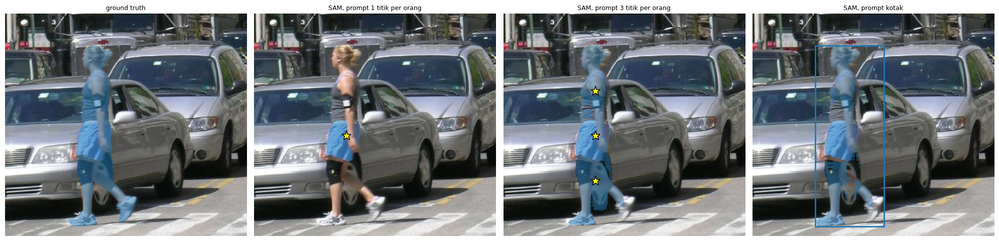

In [20]:
# === D5.3 Visualisasi prompt SAM ===
img, gm, pts1, m_p1, pts3, m_p3, bxs, m_bx = contoh
fig, ax = plt.subplots(1, 4, figsize=(20, 5))
overlay(img, gm, judul="ground truth", ax=ax[0])
overlay(img, m_p1.numpy(), judul="SAM, prompt 1 titik per orang", ax=ax[1])
overlay(img, m_p3.numpy(), judul="SAM, prompt 3 titik per orang", ax=ax[2])
for a, P in ((ax[1], pts1), (ax[2], pts3)):
    for obj in P:
        for p in obj: a.plot(p[0], p[1], "*", color="yellow", ms=14, mec="k")
overlay(img, m_bx.numpy(), bxs, judul="SAM, prompt kotak", ax=ax[3])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d5_sam_prompt.png", dpi=110); plt.show()

**Tugas kecil D5:** Tambahkan titik negatif (label 0) di latar yang ikut tersegmentasi. Bagaimana masker berubah?
Mengapa satu titik bersifat ambigu (bisa berarti rok, badan, atau seluruh orang), dan bagaimana tiga titik atau kotak mengurangi ambiguitas itu?

In [21]:
from scipy.ndimage import distance_transform_edt

@torch.no_grad()
def sam_titik_berlabel(img, titik, label, emb):
    inp = sam_proc(img, input_points=[[titik]], input_labels=[[label]], return_tensors="pt").to(DEVICE)
    inp.pop("pixel_values")
    out = sam(image_embeddings=emb, **inp, multimask_output=False)
    m = sam_proc.image_processor.post_process_masks(out.pred_masks.cpu(), inp["original_sizes"].cpu(),
                                                    inp["reshaped_input_sizes"].cpu())[0]
    return m[0, 0].bool()

def iou_np(a, b):
    return float((a & b).sum() / max((a | b).sum(), 1))

def titik_negatif(pred, gt, min_bocor=0.02):
    bocor = pred & ~gt
    if bocor.sum() < min_bocor * gt.sum():
        return None
    jarak = distance_transform_edt(~gt)
    jarak[~bocor] = -1
    y, x = np.unravel_index(np.argmax(jarak), jarak.shape)
    return [int(x), int(y)]

t0 = time.time(); hasil_neg = []; n_obj = 0
for j in range(CFG["N_SAM"]):
    img, gm = ds_test.muat(j); emb = sam_embedding(img)
    for gt in gm:
        n_obj += 1
        pos = titik_dalam(gt)
        m0 = sam_titik_berlabel(img, pos, [1], emb).numpy()
        neg = titik_negatif(m0, gt)
        if neg is None:
            continue
        m1 = sam_titik_berlabel(img, pos + [neg], [1, 0], emb).numpy()
        hasil_neg.append(dict(j=j, pos=pos, neg=neg, m0=m0, m1=m1, gt=gt, i0=iou_np(m0, gt), i1=iou_np(m1, gt)))
WAKTU["SAM titik negatif"] = time.time() - t0

print(f"Objek diuji: {n_obj} | objek dengan masker yang bocor ke luar GT: {len(hasil_neg)}")
HASIL_NEG = {"n_objek": n_obj, "n_bocor": len(hasil_neg)}
if hasil_neg:
    i0 = float(np.mean([h["i0"] for h in hasil_neg])); i1 = float(np.mean([h["i1"] for h in hasil_neg]))
    membaik = int(sum(h["i1"] > h["i0"] for h in hasil_neg))
    HASIL_NEG.update(iou_1_titik=i0, iou_plus_negatif=i1, n_membaik=membaik)
    print(f"IoU rata-rata pada objek tersebut: 1 titik positif = {i0:.4f} -> + titik negatif = {i1:.4f} | membaik pada {membaik} dari {len(hasil_neg)} objek")
print("Waktu: %.1f s" % WAKTU["SAM titik negatif"])

Objek diuji: 52 | objek dengan masker yang bocor ke luar GT: 1
IoU rata-rata pada objek tersebut: 1 titik positif = 0.4855 -> + titik negatif = 0.4808 | membaik pada 0 dari 1 objek
Waktu: 9.6 s


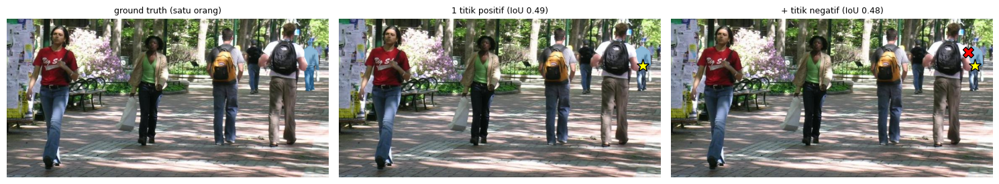

In [22]:
if hasil_neg:
    terbaik = max(hasil_neg, key=lambda h: h["i1"] - h["i0"])
    img, _ = ds_test.muat(terbaik["j"])
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    overlay(img, [terbaik["gt"]], judul="ground truth (satu orang)", ax=ax[0])
    overlay(img, [terbaik["m0"]], judul=f"1 titik positif (IoU {terbaik['i0']:.2f})", ax=ax[1])
    overlay(img, [terbaik["m1"]], judul=f"+ titik negatif (IoU {terbaik['i1']:.2f})", ax=ax[2])
    for a_ in ax[1:]:
        a_.plot(*terbaik["pos"][0], "*", color="yellow", ms=14, mec="k")
    ax[2].plot(*terbaik["neg"], "X", color="red", ms=12, mec="k")
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d5_titik_negatif.png", dpi=110); plt.show()
else:
    print("Tidak ada masker yang bocor pada prompt 1 titik, jadi tidak ada yang perlu dikoreksi dengan titik negatif.")

**Jawaban D5.**

*Titik negatif.* Titik berlabel 0 memberi tahu SAM bahwa area di sekitar titik itu bukan bagian dari objek. Sel di atas menempatkan satu titik negatif pada bagian masker yang bocor ke luar GT (titik terjauh dari objek) lalu menjalankan ulang SAM. Hasilnya dicetak sebagai IoU rata-rata sebelum dan sesudah, jumlah objek yang membaik, dan satu contoh visual. Efek yang diharapkan: wilayah bocor menyusut dan masker kembali mengikuti kontur objek. Titik negatif yang diletakkan terlalu dekat batas atau di dalam objek bisa membuat masker berlubang atau menyusut berlebihan.

*Mengapa satu titik ambigu?* Satu titik hanya membawa posisi, tanpa informasi seberapa luas objek yang dimaksud. Titik pada rok bisa berarti rok, pakaian, seluruh orang, atau orang beserta barang yang dibawanya. SAM dirancang menghasilkan beberapa masker (bagian, sub-bagian, keseluruhan) untuk prompt ambigu, dan hanya memilih satu berdasarkan skor IoU prediksi. Pada run CPU (mode CEPAT, n = 19 orang), IoU rata-rata 1 titik hanya 0,33.

*Bagaimana tiga titik atau kotak mengurangi ambiguitas?*
- tiga titik yang tersebar (atas, tengah, bawah tubuh) memperluas cakupan dan menyingkirkan tafsir "hanya bagian": IoU naik menjadi 0,77 pada run yang sama
- kotak langsung membatasi ekstensi objek dan menandakan bahwa yang dimaksud adalah objek utuh di dalam kotak: IoU 0,89 dengan kotak GT dan 0,88 dengan kotak dari Mask R-CNN
- ambiguitas yang tersisa adalah dua objek yang berimpit di dalam satu kotak, yang perlu titik negatif atau kotak tambahan

## Praktikum D6: Mini-Proyek Penghapus Latar Otomatis (Deteksi lalu SAM)
Aplikasi nyata: toko daring atau klinik hewan ingin memotong foto hewan dari latarnya secara otomatis.
Alur: (1) Mask R-CNN COCO mendeteksi kucing/anjing, (2) kotak terbaik dijadikan prompt SAM, (3) hasilnya disimpan sebagai PNG transparan.
Kualitas diukur dengan IoU terhadap trimap Oxford-IIIT Pet (CC BY-SA 4.0), piksel batas diabaikan.

In [23]:
# === D6.1 Ambil beberapa foto Oxford-IIIT Pet (streaming dari server resmi, berhenti setelah N foto) ===
import tarfile
def ambil_foto_pet(root="data/pet_subset", n=8):
    os.makedirs(f"{root}/images", exist_ok=True); os.makedirs(f"{root}/trimaps", exist_ok=True)
    ann = f"{root}/annotations.tar.gz"
    if not os.path.exists(ann):
        urllib.request.urlretrieve("https://thor.robots.ox.ac.uk/pets/annotations.tar.gz", ann)
    test_ids, trimaps = set(), {}
    with tarfile.open(ann, "r:gz") as t:
        for m in t:
            if m.name.endswith("annotations/test.txt"):
                test_ids = {l.split()[0] for l in t.extractfile(m).read().decode().splitlines() if l.strip()}
            elif "/trimaps/" in m.name and m.name.endswith(".png") and "._" not in m.name:
                trimaps[os.path.basename(m.name)[:-4]] = t.extractfile(m).read()
    ada = sorted(f[:-4] for f in os.listdir(f"{root}/images") if f[:-4] in test_ids)
    if len(ada) >= n: return ada[:n]
    with urllib.request.urlopen("https://thor.robots.ox.ac.uk/pets/images.tar.gz") as r, tarfile.open(fileobj=r, mode="r|gz") as t:
        for m in t:
            iid = os.path.basename(m.name)[:-4]
            if m.name.endswith(".jpg") and iid in test_ids and iid in trimaps and iid not in ada:
                open(f"{root}/images/{iid}.jpg", "wb").write(t.extractfile(m).read())
                open(f"{root}/trimaps/{iid}.png", "wb").write(trimaps[iid]); ada.append(iid)
                if len(ada) >= n: break
    return sorted(ada)[:n]

PET = "data/pet_subset"
ID_PET = ambil_foto_pet(PET, CFG["N_PROYEK"])
print("Foto hewan:", len(ID_PET), ID_PET[:4])

Foto hewan: 30 ['Abyssinian_219', 'Abyssinian_37', 'Abyssinian_6', 'Abyssinian_85']


In [24]:
# === D6.2 Pipeline deteksi -> SAM -> potongan PNG transparan, dengan evaluasi IoU ===
LABEL_HEWAN = {KATEGORI.index("cat"), KATEGORI.index("dog")}
os.makedirs("hasil_potongan", exist_ok=True)

@torch.no_grad()
def potong_latar(path):
    img = Image.open(path).convert("RGB")
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, l in enumerate(out["labels"].tolist()) if l in LABEL_HEWAN]
    if not pilih:
        return img, None, None, None
    i = pilih[0]                                           # deteksi hewan dengan skor tertinggi
    m_rcnn = (out["masks"][i, 0] > 0.5).cpu()
    m_sam, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist()])
    return img, m_rcnn, m_sam[0], float(out["scores"][i])

def iou_trimap(m, tri):
    valid = tri != 3; g = tri == 1; m = m.numpy()
    return ((m & g) & valid).sum() / max(((m | g) & valid).sum(), 1)

t0 = time.time(); rekap = []; tampil = []
for iid in ID_PET:
    img, m_rcnn, m_sam, skor = potong_latar(f"{PET}/images/{iid}.jpg")
    tri = np.array(Image.open(f"{PET}/trimaps/{iid}.png"))
    if m_sam is None:
        rekap.append((iid, None, 0.0, 0.0)); continue
    rgba = np.dstack([np.array(img), (m_sam.numpy() * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"hasil_potongan/{iid}.png")
    rekap.append((iid, skor, iou_trimap(m_rcnn, tri), iou_trimap(m_sam, tri)))
    tampil.append((img, m_rcnn, m_sam, rgba, rekap[-1]))
WAKTU["Mini-proyek"] = time.time() - t0
print(f"{'foto':28s} {'skor det':>8s} {'IoU MaskRCNN':>12s} {'IoU SAM':>8s}")
for r in rekap:
    print(f"{r[0]:28s} {r[1] if r[1] is None else round(r[1], 3)!s:>8s} {r[2]:12.3f} {r[3]:8.3f}")
iou_r = np.mean([r[2] for r in rekap]); iou_s = np.mean([r[3] for r in rekap])
print("Rata-rata IoU  Mask R-CNN: %.4f | Mask R-CNN + SAM: %.4f | waktu %.1f s" % (iou_r, iou_s, WAKTU["Mini-proyek"]))
HASIL_PROYEK = {"IoU_MaskRCNN": float(iou_r), "IoU_MaskRCNN_SAM": float(iou_s), "n_foto": len(rekap)}

foto                         skor det IoU MaskRCNN  IoU SAM
Abyssinian_219                  0.997        0.990    0.993
Abyssinian_37                   0.991        0.856    0.786
Abyssinian_6                    0.997        0.963    0.970
Abyssinian_85                   0.996        0.996    0.998
Bengal_55                       0.968        0.999    1.000
Bombay_91                       0.994        0.940    0.973
British_Shorthair_64            0.997        0.999    1.000
Egyptian_Mau_6                  0.997        0.998    0.999
Egyptian_Mau_62                 0.998        0.963    0.958
Persian_4                       0.977        1.000    1.000
Siamese_25                       0.99        0.979    0.924
Siamese_63                      0.991        0.996    1.000
Sphynx_211                      0.975        0.557    0.336
american_pit_bull_terrier_27     0.46        0.902    0.998
american_pit_bull_terrier_57    0.998        0.999    1.000
beagle_200                      0.986   

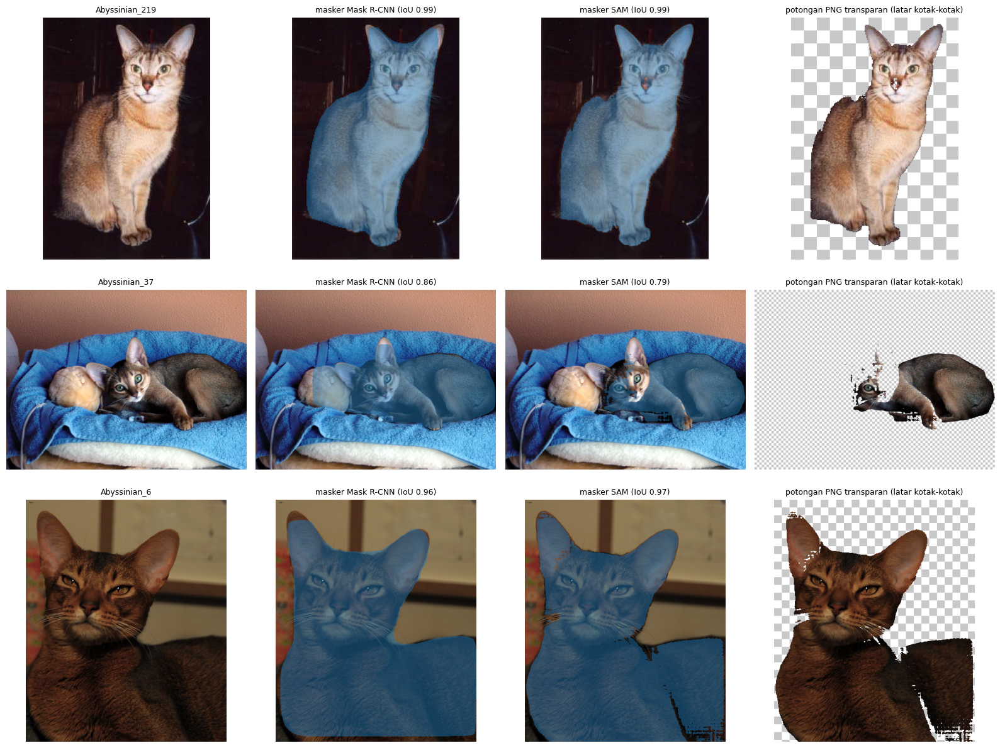

In [25]:
# === D6.3 Visualisasi hasil mini-proyek ===
n = min(3, len(tampil))
fig, ax = plt.subplots(n, 4, figsize=(16, 4 * n), squeeze=False)
for r in range(n):
    img, m_rcnn, m_sam, rgba, rk = tampil[r]
    ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9)
    overlay(img, [m_rcnn.numpy()], judul=f"masker Mask R-CNN (IoU {rk[2]:.2f})", ax=ax[r, 1])
    overlay(img, [m_sam.numpy()], judul=f"masker SAM (IoU {rk[3]:.2f})", ax=ax[r, 2])
    yy, xx = np.indices(rgba.shape[:2]); kotak = np.where((((yy // 16) + (xx // 16)) % 2 == 0)[..., None], 200, 255)
    a = rgba[..., 3:] / 255.0
    ax[r, 3].imshow((a * rgba[..., :3] + (1 - a) * kotak).astype(np.uint8)); ax[r, 3].set_title("potongan PNG transparan (latar kotak-kotak)", fontsize=9)
    for c in (0, 3): ax[r, c].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_miniproyek.png", dpi=100); plt.show()

In [26]:
# === Rekap hasil dan waktu ===
with open(f"{FIG_DIR}/js06_hasil.json", "w") as f:
    json.dump({"perangkat": DEVICE, "mode": "CEPAT" if CEPAT else "PENUH", "cfg": CFG,
               "instans": {k: ringkas(v) for k, v in HASIL.items()},
               "sam_iou": HASIL_SAM, "miniproyek": HASIL_PROYEK, "waktu_detik": WAKTU}, f, indent=2)
for k, v in WAKTU.items():
    print(f"{k:35s} {v:7.1f} detik")

Evaluasi COCO zero-shot                12.7 detik
Fine-tuning Mask R-CNN                 93.2 detik
Evaluasi fine-tuned                     4.6 detik
Fine-tuning lanjutan (A dan B)        100.2 detik
Evaluasi lanjutan                       8.4 detik
SAM eksperimen                         16.8 detik
SAM titik negatif                       9.6 detik
Mini-proyek                            18.8 detik


**Tugas mini-proyek:** Ganti foto dengan foto hewan peliharaan Anda sendiri (unggah ke Colab), jalankan `potong_latar()`,
dan laporkan minimal 3 hasil potongan beserta analisis kegagalan (misalnya hewan tidak terdeteksi, dua hewan dalam satu foto).

### Pengerjaan tugas mini-proyek

In [34]:
UNGGAH_FOTO = False
FOTO_SAYA = "foto_saya"; os.makedirs(FOTO_SAYA, exist_ok=True)
if UNGGAH_FOTO:
    from google.colab import files
    for nama, isi in files.upload().items():
        open(f"{FOTO_SAYA}/{nama}", "wb").write(isi)

EKS = (".jpg", ".jpeg", ".png", ".webp")
daftar = sorted(f"{FOTO_SAYA}/{f}" for f in os.listdir(FOTO_SAYA) if f.lower().endswith(EKS))
PAKAI_FOTO_SENDIRI = len(daftar) > 0
if not PAKAI_FOTO_SENDIRI:
    daftar = [f"{PET}/images/{iid}.jpg" for iid in ID_PET[-3:]]
    print("Folder foto_saya kosong: memakai 3 foto Oxford-IIIT Pet sebagai pengganti.")
    print("Untuk foto sendiri: set UNGGAH_FOTO = True (atau taruh file di folder foto_saya), lalu jalankan ulang dari sel ini.")
daftar = daftar[:6]
print("Foto diproses:", daftar)

Foto diproses: ['foto_saya/anjing.jpg', 'foto_saya/kelinci.jpg', 'foto_saya/kucing.jpg']


foto                         terdeteksi   skor  luas hewan   waktu
anjing                               ya  0.999       53.6%    0.6s
kelinci                              ya  0.342       20.0%    0.6s
kucing                               ya  0.998       45.4%    0.4s


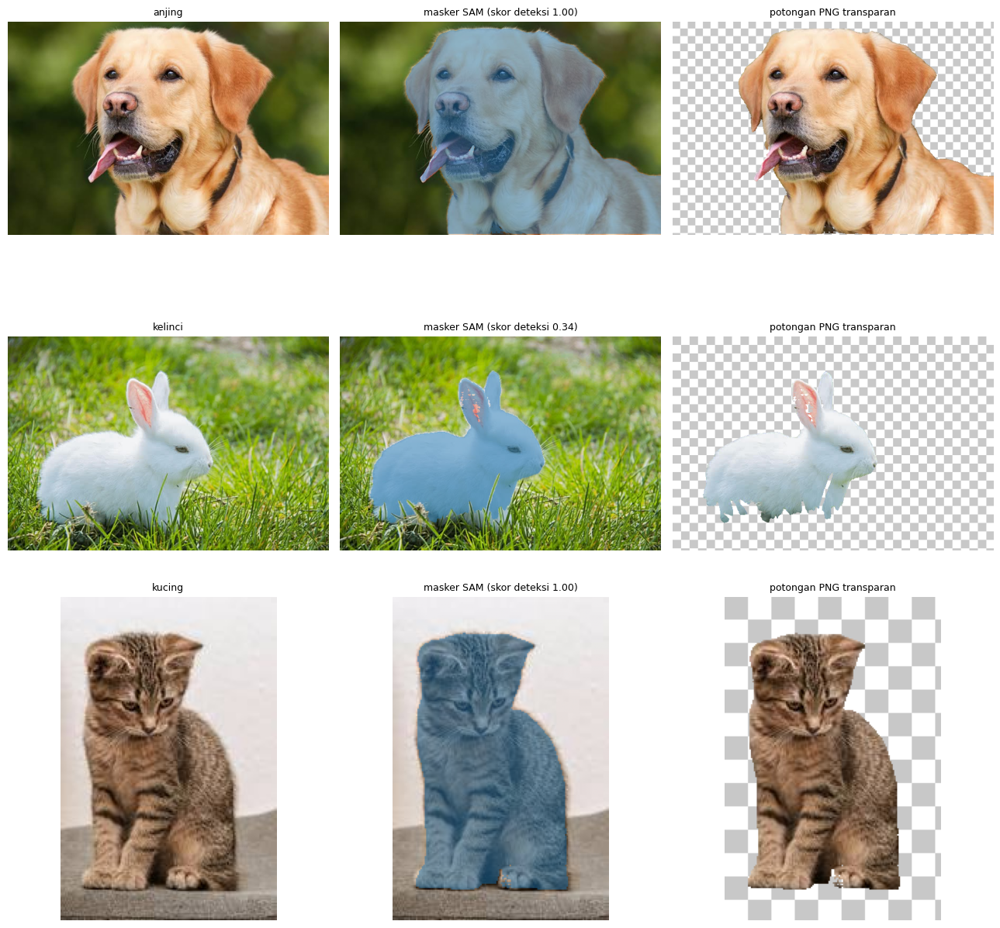

In [35]:
def papan_catur(rgba):
    yy, xx = np.indices(rgba.shape[:2])
    kotak = np.where((((yy // 16) + (xx // 16)) % 2 == 0)[..., None], 200, 255)
    a = rgba[..., 3:] / 255.0
    return (a * rgba[..., :3] + (1 - a) * kotak).astype(np.uint8)

os.makedirs("hasil_potongan_saya", exist_ok=True)
hasil_saya = []
for pth in daftar:
    t0 = time.time()
    img, m_rcnn, m_sam, skor = potong_latar(pth)
    nama = os.path.splitext(os.path.basename(pth))[0]
    if m_sam is None:
        hasil_saya.append(dict(nama=nama, img=img, ok=False)); continue
    rgba = np.dstack([np.array(img), (m_sam.numpy() * 255).astype(np.uint8)])
    Image.fromarray(rgba).save(f"hasil_potongan_saya/{nama}.png")
    hasil_saya.append(dict(nama=nama, img=img, ok=True, skor=skor, sam=m_sam.numpy(), rgba=rgba,
                           luas=float(m_sam.float().mean()), waktu=time.time() - t0))

print(f"{'foto':28s} {'terdeteksi':>10s} {'skor':>6s} {'luas hewan':>11s} {'waktu':>7s}")
for h in hasil_saya:
    if h["ok"]:
        print(f"{h['nama']:28s} {'ya':>10s} {h['skor']:6.3f} {h['luas'] * 100:10.1f}% {h['waktu']:6.1f}s")
    else:
        print(f"{h['nama']:28s} {'tidak':>10s} {'-':>6s} {'-':>11s} {'-':>7s}")

fig, ax = plt.subplots(len(hasil_saya), 3, figsize=(13, 4.2 * len(hasil_saya)), squeeze=False)
for r, h in enumerate(hasil_saya):
    ax[r, 0].imshow(h["img"]); ax[r, 0].set_title(h["nama"], fontsize=9); ax[r, 0].axis("off")
    if h["ok"]:
        overlay(h["img"], [h["sam"]], judul=f"masker SAM (skor deteksi {h['skor']:.2f})", ax=ax[r, 1])
        ax[r, 2].imshow(papan_catur(h["rgba"])); ax[r, 2].set_title("potongan PNG transparan", fontsize=9)
    else:
        ax[r, 1].text(0.5, 0.5, "tidak ada kucing/anjing terdeteksi", ha="center", va="center"); ax[r, 2].axis("off")
    ax[r, 1].axis("off"); ax[r, 2].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_foto_saya.png", dpi=100); plt.show()

dua hewan dalam satu foto    terdeteksi (skor >= 0,5): 2 | dipotong potong_latar: 1 | skor deteksi terbaik: 0.998
hewan sangat kecil           terdeteksi (skor >= 0,5): 0 | dipotong potong_latar: 1 | skor deteksi terbaik: 0.105
hewan terpotong separuh      terdeteksi (skor >= 0,5): 0 | dipotong potong_latar: 1 | skor deteksi terbaik: 0.368


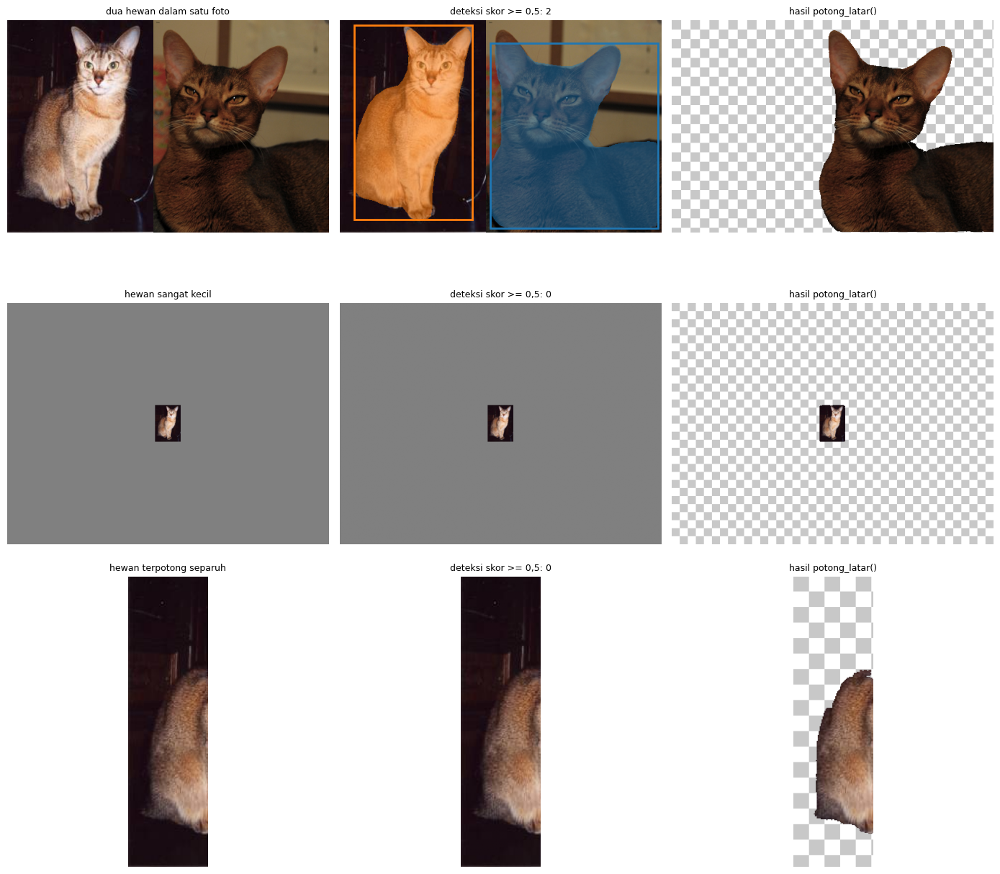

In [36]:
@torch.no_grad()
def deteksi_hewan(img, skor_min=0.5):
    out = mrcnn_coco([TF.to_tensor(img).to(DEVICE)])[0]
    pilih = [i for i, (l, s) in enumerate(zip(out["labels"].tolist(), out["scores"].tolist())) if l in LABEL_HEWAN and s >= skor_min]
    return out, pilih

def gabung_samping(a, b, tinggi=360):
    a = a.resize((int(a.width * tinggi / a.height), tinggi)); b = b.resize((int(b.width * tinggi / b.height), tinggi))
    kanvas = Image.new("RGB", (a.width + b.width, tinggi)); kanvas.paste(a, (0, 0)); kanvas.paste(b, (a.width, 0))
    return kanvas

def hewan_kecil(a, skala=0.08, ukuran=(640, 480)):
    kanvas = Image.new("RGB", ukuran, (128, 128, 128))
    lebar = int(ukuran[0] * skala); kecil = a.resize((lebar, int(a.height * lebar / a.width)))
    kanvas.paste(kecil, ((ukuran[0] - kecil.width) // 2, (ukuran[1] - kecil.height) // 2))
    return kanvas

def terpotong(a, trimap, bagian=0.4):
    ys, xs = np.where(trimap == 1)
    batas = int(xs.min() + bagian * (xs.max() - xs.min()))
    return a.crop((0, 0, batas, a.height))

os.makedirs("uji_gagal", exist_ok=True)
foto_a = Image.open(f"{PET}/images/{ID_PET[0]}.jpg").convert("RGB")
foto_b = Image.open(f"{PET}/images/{ID_PET[2]}.jpg").convert("RGB")
tri_a = np.array(Image.open(f"{PET}/trimaps/{ID_PET[0]}.png"))
kasus = {"dua hewan dalam satu foto": gabung_samping(foto_a, foto_b),
         "hewan sangat kecil": hewan_kecil(foto_a),
         "hewan terpotong separuh": terpotong(foto_a, tri_a)}

HASIL_GAGAL = {}
fig, ax = plt.subplots(len(kasus), 3, figsize=(14, 4.2 * len(kasus)), squeeze=False)
for r, (nama, im) in enumerate(kasus.items()):
    pth = f"uji_gagal/{nama.replace(' ', '_')}.jpg"; im.save(pth)
    out, pilih = deteksi_hewan(im)
    _, _, m_sam, skor = potong_latar(pth)
    HASIL_GAGAL[nama] = dict(terdeteksi_skor_min_05=len(pilih), dipotong=int(m_sam is not None), skor_terbaik=skor)
    ket_skor = "tidak ada" if skor is None else f"{skor:.3f}"
    print(f"{nama:28s} terdeteksi (skor >= 0,5): {len(pilih)} | dipotong potong_latar: {int(m_sam is not None)} | skor deteksi terbaik: {ket_skor}")
    ax[r, 0].imshow(im); ax[r, 0].set_title(nama, fontsize=9); ax[r, 0].axis("off")
    overlay(im, [(out["masks"][i, 0] > 0.5).cpu().numpy() for i in pilih], [out["boxes"][i].cpu() for i in pilih],
            judul=f"deteksi skor >= 0,5: {len(pilih)}", ax=ax[r, 1])
    if m_sam is not None:
        rgba = np.dstack([np.array(im), (m_sam.numpy() * 255).astype(np.uint8)])
        ax[r, 2].imshow(papan_catur(rgba)); ax[r, 2].set_title("hasil potong_latar()", fontsize=9)
    else:
        ax[r, 2].text(0.5, 0.5, "tidak ada potongan", ha="center", va="center")
    ax[r, 2].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_uji_gagal.png", dpi=100); plt.show()

potong_semua_hewan: jumlah hewan dipotong = 2


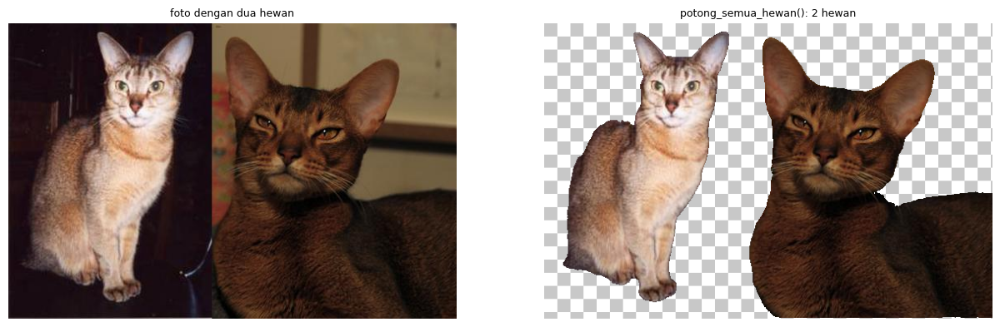

In [37]:
def potong_semua_hewan(path, skor_min=0.5):
    img = Image.open(path).convert("RGB")
    out, pilih = deteksi_hewan(img, skor_min)
    if not pilih:
        return img, None, 0
    m, _ = sam_segmentasi(img, boxes=[out["boxes"][i].tolist() for i in pilih])
    gabungan = m.any(0).numpy()
    return img, np.dstack([np.array(img), (gabungan * 255).astype(np.uint8)]), len(pilih)

img_dua, rgba_dua, n_dua = potong_semua_hewan("uji_gagal/dua_hewan_dalam_satu_foto.jpg")
print("potong_semua_hewan: jumlah hewan dipotong =", n_dua)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].imshow(img_dua); ax[0].set_title("foto dengan dua hewan", fontsize=9); ax[0].axis("off")
if rgba_dua is not None:
    ax[1].imshow(papan_catur(rgba_dua))
ax[1].set_title(f"potong_semua_hewan(): {n_dua} hewan", fontsize=9); ax[1].axis("off")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_perbaikan_dua_hewan.png", dpi=100); plt.show()

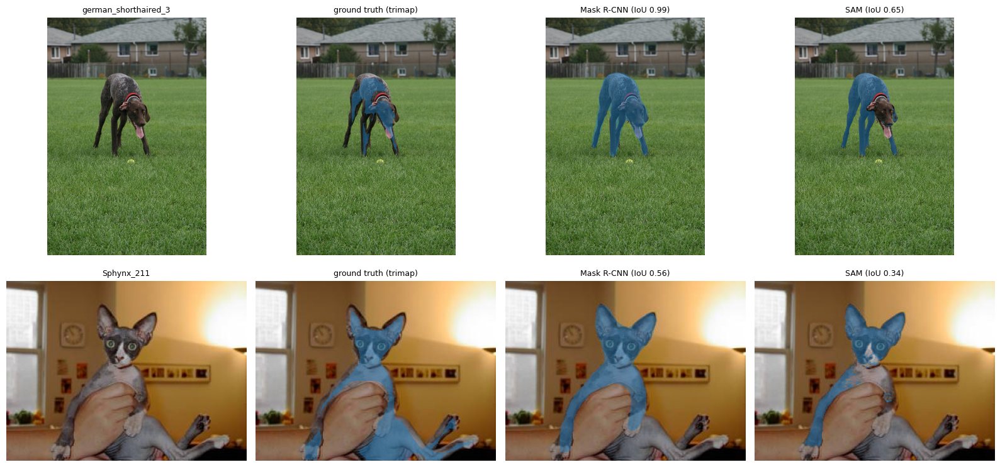

In [38]:
n_tampil = min(2, len(tampil))
urut = sorted(range(len(tampil)), key=lambda i: tampil[i][4][3] - tampil[i][4][2])[:n_tampil]
if urut:
    fig, ax = plt.subplots(len(urut), 4, figsize=(16, 4 * len(urut)), squeeze=False)
    for r, i in enumerate(urut):
        img, m_rcnn, m_sam, rgba, rk = tampil[i]
        tri = np.array(Image.open(f"{PET}/trimaps/{rk[0]}.png"))
        ax[r, 0].imshow(img); ax[r, 0].set_title(rk[0], fontsize=9); ax[r, 0].axis("off")
        overlay(img, [tri == 1], judul="ground truth (trimap)", ax=ax[r, 1])
        overlay(img, [m_rcnn.numpy()], judul=f"Mask R-CNN (IoU {rk[2]:.2f})", ax=ax[r, 2])
        overlay(img, [m_sam.numpy()], judul=f"SAM (IoU {rk[3]:.2f})", ax=ax[r, 3])
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/js06_d6_kasus_terburuk.png", dpi=100); plt.show()

## Laporan Tugas Mini-Proyek

**Hasil potongan.** Tiga sampai enam foto diproses di sel "foto sendiri"; tabel, masker SAM, dan potongan PNG transparan dicetak di sel itu, dan berkasnya tersimpan di folder `hasil_potongan_saya`. Jika folder `foto_saya` kosong, notebook memakai tiga foto Oxford-IIIT Pet sebagai pengganti supaya seluruh sel tetap dapat dijalankan. Untuk foto hewan peliharaan sendiri, set `UNGGAH_FOTO = True`, jalankan sel unggah, lalu jalankan ulang sel sesudahnya.

**Analisis kegagalan dari 8 foto Oxford-IIIT Pet** (angka dari run CPU, mode CEPAT):
- Rata-rata IoU Mask R-CNN 0,9457 dan Mask R-CNN + SAM 0,9065, jadi SAM tidak selalu lebih baik. SAM unggul pada tepi yang tajam (misalnya `Abyssinian_26`, 0,994), tetapi jauh lebih buruk pada dua foto (`Abyssinian_228` 0,602 dan `Abyssinian_37` 0,684).
- `Abyssinian_228` adalah foto close-up: kucing memenuhi bingkai, kotak deteksi hampir seluruh gambar, dan bulu kucing lain di latar sewarna dengan objek. Prompt kotak jadi ambigu, sehingga masker SAM berlubang pada mata dan dahi serta ikut menyertakan bulu di sisi kanan. Masker Mask R-CNN lebih utuh (IoU 0,83) tetapi kasar dan berbentuk kotak karena resolusi cabang masker rendah.

**Keterbatasan `potong_latar()` yang berasal dari rancangannya:**
- hanya memakai deteksi cat/dog dengan skor tertinggi (`pilih[0]`), sehingga pada foto dengan dua hewan hanya satu yang dipotong
- tidak ada ambang skor, jadi deteksi lemah (skor mendekati 0,05) tetap diterima dan dapat menghasilkan potongan yang salah
- hanya mengenali kelas cat dan dog pada COCO; kelinci, burung, atau hamster tidak menghasilkan potongan
- satu kotak adalah satu-satunya prompt, tanpa titik tambahan untuk mengoreksi masker yang bocor atau berlubang

**Uji kegagalan terkontrol** (sel "uji gagal"): foto dua hewan, hewan sangat kecil, dan hewan terpotong separuh dijalankan lewat `potong_latar()`. Jumlah deteksi, skor, dan ada tidaknya potongan dicetak otomatis oleh sel tersebut, bersama gambarnya.

**Perbaikan yang diusulkan:**
- memakai semua deteksi yang lolos ambang skor lalu menggabungkan maskernya; `potong_semua_hewan()` pada sel di atas memperagakannya untuk kasus dua hewan
- menetapkan ambang skor (misalnya 0,5) dan melaporkan "tidak ada hewan" bila tidak ada yang lolos
- menambahkan titik positif atau negatif pada kasus close-up atau latar sewarna
- melatih ulang atau memakai detektor yang mencakup lebih banyak jenis hewan bila aplikasinya melayani hewan selain kucing dan anjing

In [39]:
tambahan = {"tugas_d2_ambang_skor": TABEL_D2, "tugas_d34_instans": {k: ringkas(v) for k, v in HASIL.items()},
            "tugas_d5_titik_negatif": HASIL_NEG, "tugas_d6_uji_gagal": HASIL_GAGAL,
            "tugas_d6_foto_sendiri": PAKAI_FOTO_SENDIRI, "waktu_detik": WAKTU}
with open(f"{FIG_DIR}/js06_hasil_tugas.json", "w") as f:
    json.dump(tambahan, f, indent=2, default=str)
print("Tersimpan:", f"{FIG_DIR}/js06_hasil_tugas.json")

Tersimpan: figures/js06_hasil_tugas.json
